### Data Analysis Summary

The goal of this analysis was to understand how household shopping behavior varies and whether the selected features are suitable for customer segmentation. The dataset contains 2,500 households with no missing values.

Many features are strongly right-skewed, with a small number of households showing much higher spending, frequency, or purchase volume than the rest. Total spend generally increases with the number of trips, but households with similar trip counts can still spend very different amounts. Recency and average days between trips also appear to capture different aspects of engagement.

Log transformations improved the distributions of total spend and average basket value without removing high-value households. Total units purchased and average basket size contain especially large values, making their relationship difficult to interpret on the original scale. Some features are also mathematically related, so their potential overlap will need to be considered before clustering.

Overall, the data shows enough variation in spending, frequency, recency, and basket behavior to support household segmentation.

#### Import libraries

In [1]:
# Core analysis libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Improve plot styling
sns.set()

# Show all columns during EDA
pd.set_option('display.max_columns', None)

# Display all dataframes generated within a cell
from IPython.display import display

In [2]:
# File path locations
from pathlib import Path

# File paths
PROJECT_ROOT = Path.cwd().resolve().parent
CLEAN_DATA_DIR = PROJECT_ROOT / "data/clean_data"
RAW_DATA_DIR = PROJECT_ROOT / "data/raw_data"
MODELS_DIR = PROJECT_ROOT / "models"
SRC_DIR = PROJECT_ROOT / "src"
DEPLOYMENT_DIR = PROJECT_ROOT / "deployment"

#### Import data

In [3]:
# Import data and show first five rows
hh_shopping = pd.read_parquet(CLEAN_DATA_DIR / "01_household_shopping.parquet")
hh_shopping.head()

,household_key,num_trips,recency_days,total_spend,avg_basket_value,total_units_purchased,avg_days_between_trips,avg_basket_size
0,1,86,5,4330.16,50.35,1997,7.7,23.2
1,2,45,43,1954.34,43.43,834,12.8,18.5
2,3,47,8,2653.21,56.45,8540,12.8,181.7
3,4,30,84,1200.11,40.00,382,18.0,12.7
4,5,40,8,779.06,19.48,245,15.8,6.1


In [4]:
# Number of rows, columns
hh_shopping.shape

(2500, 8)

In [5]:
# Data types and nulls
hh_shopping_types_null_counts = pd.DataFrame()
hh_shopping_types_null_counts["Data Type"] = hh_shopping.dtypes
hh_shopping_types_null_counts["Count of Nulls"] = hh_shopping.isna().sum()
hh_shopping_types_null_counts

,Data Type,Count of Nulls
household_key,int64,0
num_trips,int64,0
recency_days,int64,0
total_spend,float64,0
avg_basket_value,float64,0
total_units_purchased,int64,0
avg_days_between_trips,float64,0
avg_basket_size,float64,0


In [6]:
hh_shopping.describe().round(2)

,household_key,num_trips,recency_days,total_spend,avg_basket_value,total_units_purchased,avg_days_between_trips,avg_basket_size
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,1250.50,110.59,25.57,3222.99,31.62,104274.25,15.94,726.70
std,721.83,115.67,62.79,3349.03,19.05,244456.08,34.50,1239.62
min,1.00,1.00,0.00,8.17,2.39,5.00,0.50,1.60
25%,625.75,39.00,1.00,970.74,18.33,770.00,4.50,13.50
50%,1250.50,79.00,6.00,2157.75,27.42,11084.50,8.20,137.45
75%,1875.25,142.25,20.00,4413.32,40.55,87640.00,16.50,965.75
max,2500.00,1300.00,657.00,38319.79,165.83,4479917.00,711.00,16322.50


#### Pairplot
Most of the features are right-skewed, with a few households showing much higher activity than the rest.

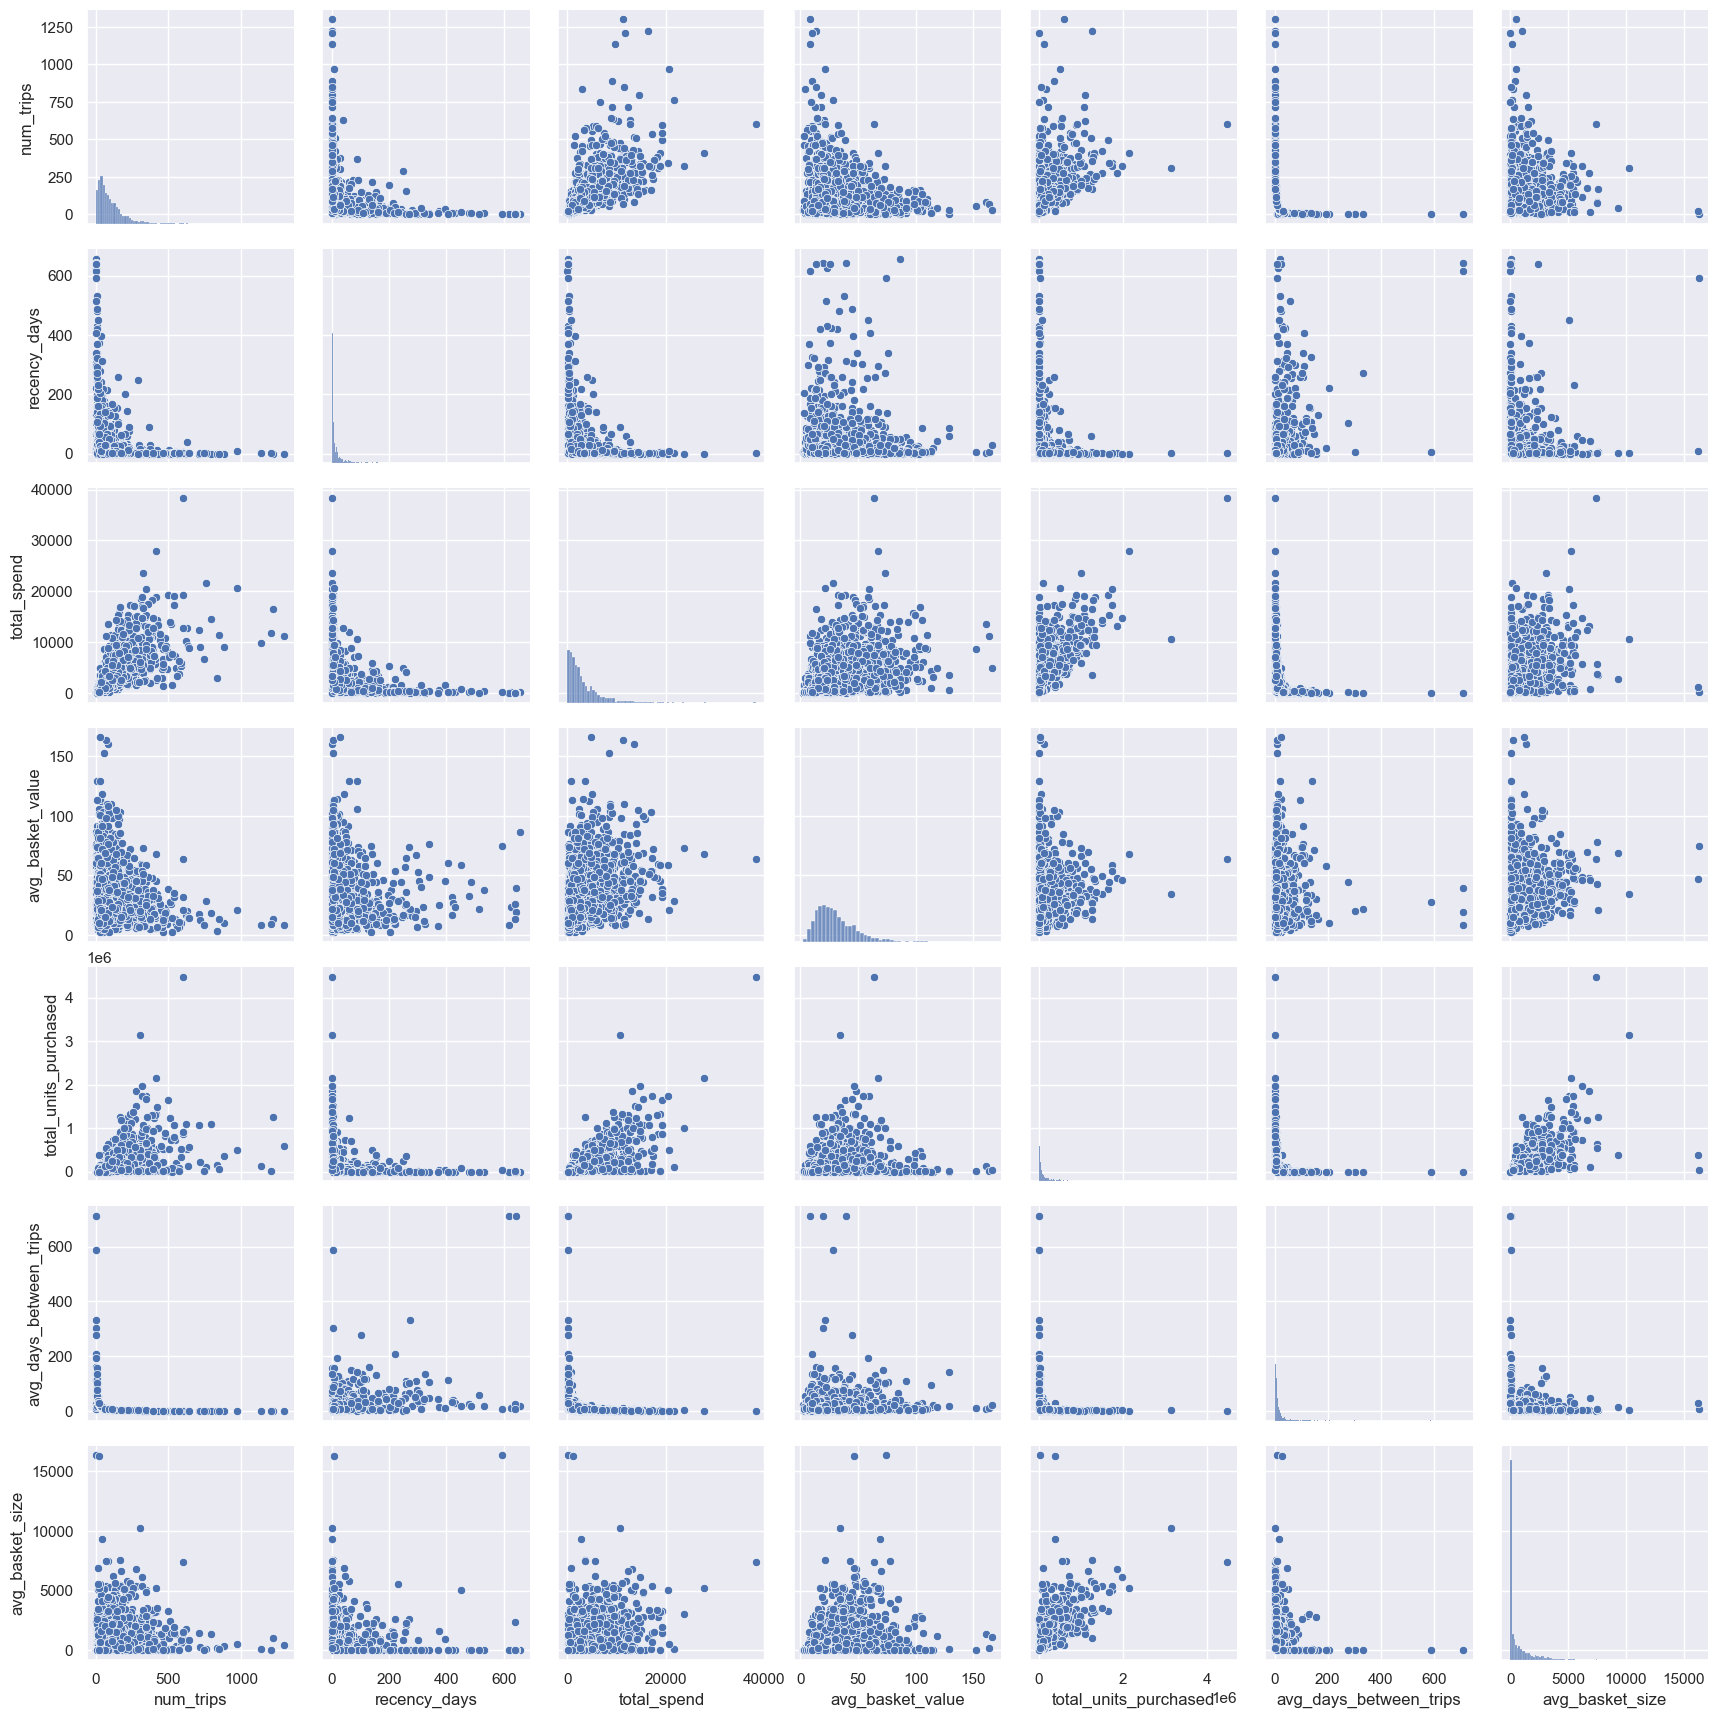

In [7]:
sns.pairplot(hh_shopping.drop("household_key", axis=1))
plt.show()

#### Total spend quantiles

In [8]:
total_spend_upper_quants = pd.DataFrame(
    hh_shopping["total_spend"].quantile([0.95, 0.99, 0.995, 0.999]).round(2)
).rename_axis("Quantile")

total_spend_lower_quants = pd.DataFrame(
    hh_shopping["total_spend"].quantile([0.01, 0.05, 0.10]).round(2)
).rename_axis("Quantile")

display(total_spend_upper_quants)
display(total_spend_lower_quants)

,total_spend
Quantile,
0.950,9754.14
0.990,15325.02
0.995,17930.07
0.999,22656.09


,total_spend
Quantile,
0.01,84.21
0.05,240.81
0.10,389.88


#### Total spend vs. number of trips
Households that shop more often usually spend more, although trip count does not explain all of the difference in total spending.

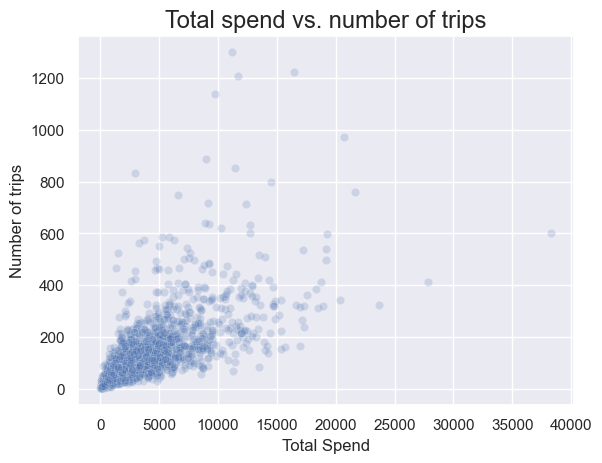

In [9]:
# Scatterplot of "total_spend" and "num_trips"
sns.scatterplot(
    data=hh_shopping, 
    x="total_spend", 
    y="num_trips",
    alpha=0.2
)
plt.title("Total spend vs. number of trips", fontsize=17)
plt.xlabel("Total Spend")
plt.ylabel("Number of trips")
plt.show()

#### Average basket value vs. number of trips
Frequent shoppers tend to have smaller average baskets, while some less-frequent shoppers spend more per trip.

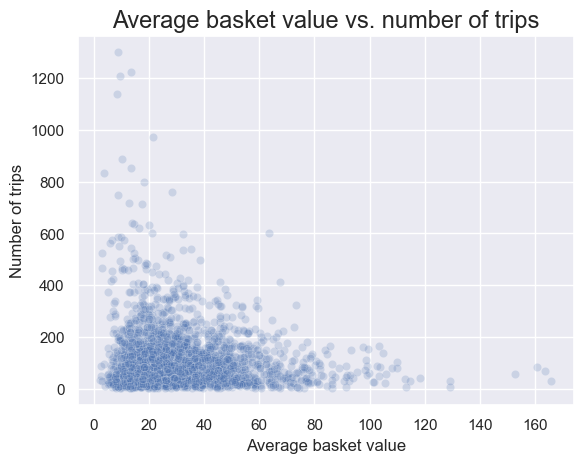

In [10]:
sns.scatterplot(
    data=hh_shopping, 
    x="avg_basket_value", 
    y="num_trips",
    alpha=0.2
)
plt.title("Average basket value vs. number of trips", fontsize=17)
plt.xlabel("Average basket value")
plt.ylabel("Number of trips")
plt.show()

#### Average basket value distribution
Most households have moderate basket values, with a small number spending much more per trip.

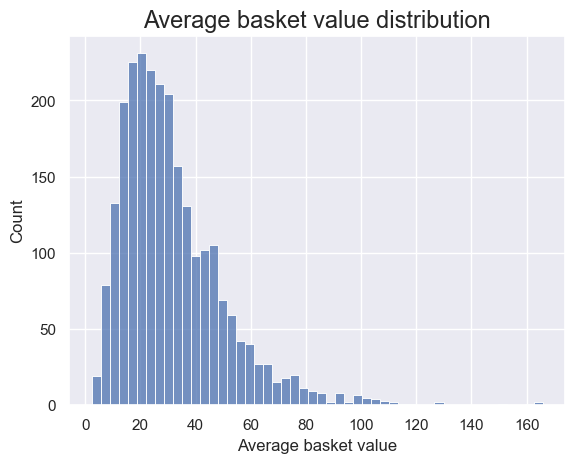

In [11]:
sns.histplot(hh_shopping["avg_basket_value"], bins=50)
plt.title("Average basket value distribution", fontsize=17)
plt.xlabel("Average basket value")
plt.ylabel("Count")
plt.show()

#### Average basket value quantiles

In [12]:
avg_basket_value_upper_quants = pd.DataFrame(
    hh_shopping["avg_basket_value"].quantile([0.95, 0.99, 0.995, 0.999]).round(2)
).rename_axis("Quantile")

avg_basket_value_lower_quants = pd.DataFrame(
    hh_shopping["avg_basket_value"].quantile([0.01, 0.05, 0.10]).round(2)
).rename_axis("Quantile")

display(avg_basket_value_lower_quants)
display(avg_basket_value_upper_quants)

,avg_basket_value
Quantile,
0.01,6.20
0.05,9.87
0.10,12.53


,avg_basket_value
Quantile,
0.950,67.60
0.990,99.03
0.995,107.00
0.999,156.54


#### Log-transformed total spend
The log transformation makes total spend less skewed and reduces the impact of the highest-spending households.

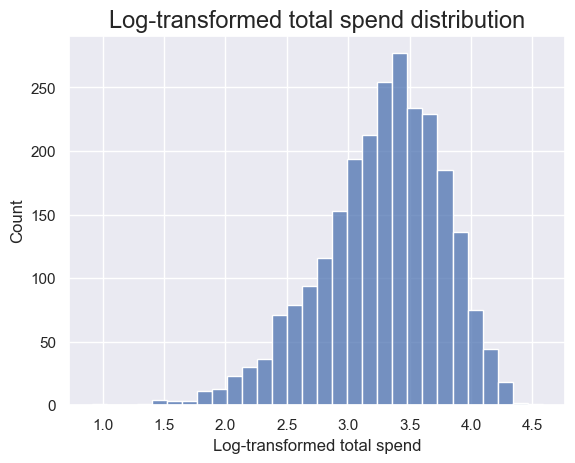

In [13]:
# Log-transformed total spend
hh_shopping["log10_total_spend"] = np.log10(hh_shopping["total_spend"])

# Histogram
sns.histplot(hh_shopping["log10_total_spend"], bins=30)
plt.title("Log-transformed total spend distribution", fontsize=17)
plt.xlabel("Log-transformed total spend")
plt.ylabel("Count")
plt.show()

#### Log-transformed average basket value
The log transformation makes average basket value more evenly distributed while keeping the differences between households.

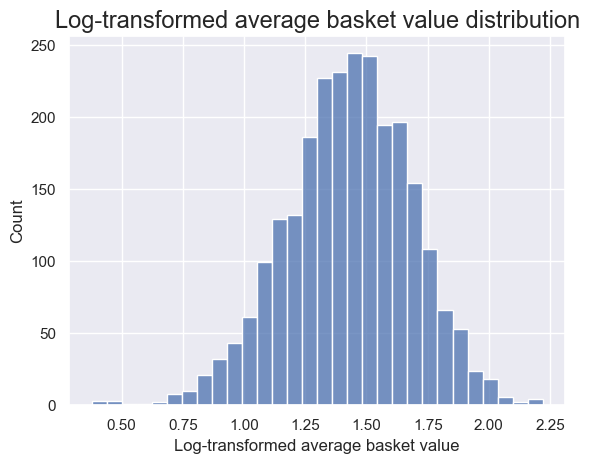

In [14]:
# Log-transformed avg_basket_value
hh_shopping["log10_avg_basket_value"] = np.log10(hh_shopping["avg_basket_value"])

# Histogram
sns.histplot(hh_shopping["log10_avg_basket_value"], bins=30)
plt.title("Log-transformed average basket value distribution", fontsize=17)
plt.xlabel("Log-transformed average basket value")
plt.ylabel("Count")
plt.show()

#### Log-transformed average basket size
Log-transforming `avg_basket_size` creates a bimodal distribution. For clustering, this may be help with separating households into different purchasing-volume groups.

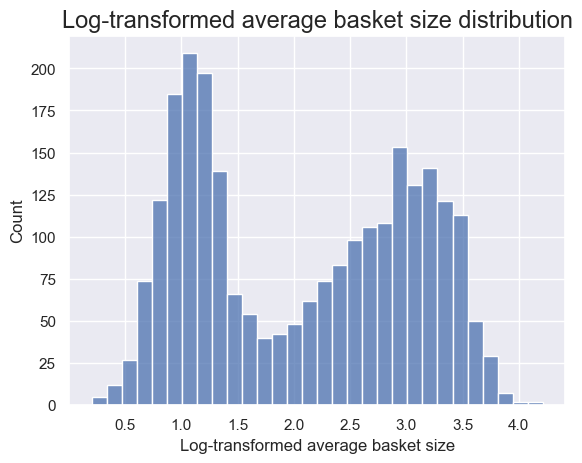

In [15]:
# Log-transformed avg_basket_size
hh_shopping["log10_avg_basket_size"] = np.log10(hh_shopping["avg_basket_size"])

# Histogram
sns.histplot(hh_shopping["log10_avg_basket_size"], bins=30)
plt.title("Log-transformed average basket size distribution", fontsize=17)
plt.xlabel("Log-transformed average basket size")
plt.ylabel("Count")
plt.show()

#### Recency distribution
Recency will remain on its original scale because the concentration near zero reflects meaningful recent activity, while larger values help distinguish households that have been inactive for longer periods.

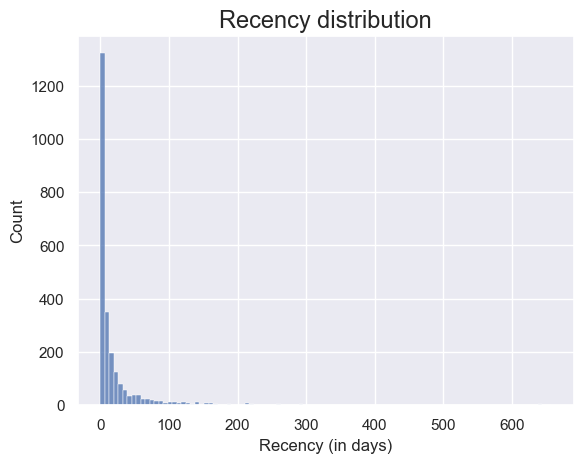

In [16]:
# Histogram
sns.histplot(hh_shopping["recency_days"], bins=100)
plt.title("Recency distribution", fontsize=17)
plt.xlabel("Recency (in days)")
plt.ylabel("Count")
plt.show()

#### Recency vs. average days between trips
Recency and average days between trips appear to capture different parts of household shopping behavior.

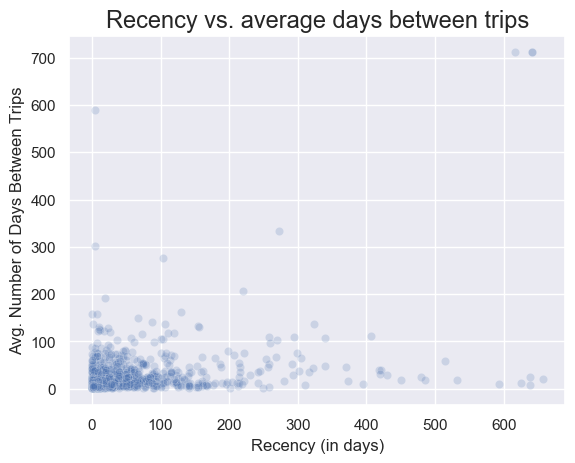

In [17]:
# Scatterplot of "avg_days_between_trips" and "recency_days"
sns.scatterplot(
    data=hh_shopping, 
    x="recency_days", 
    y="avg_days_between_trips",
    alpha=0.2
)
plt.title("Recency vs. average days between trips", fontsize=17)
plt.xlabel("Recency (in days)")
plt.ylabel("Avg. Number of Days Between Trips")
plt.show()

#### Number of trips distribution
Most households made a moderate number of trips, while a small group shopped much more frequently.

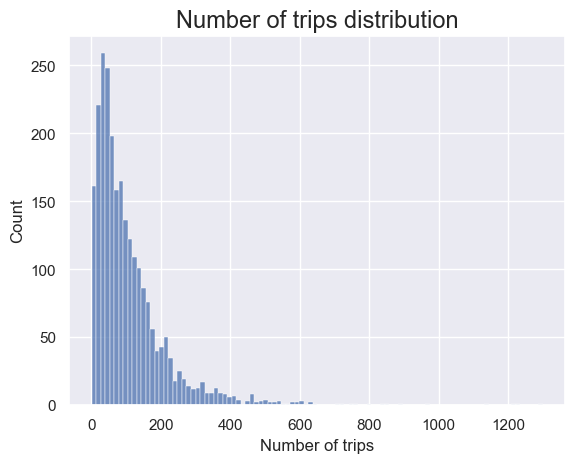

In [18]:
sns.histplot(hh_shopping["num_trips"], bins=100)
plt.title("Number of trips distribution", fontsize=17)
plt.xlabel("Number of trips")
plt.ylabel("Count")
plt.show()

#### Total units purchased distribution
Most households purchased far fewer units than the small number of households at the upper end of the distribution.

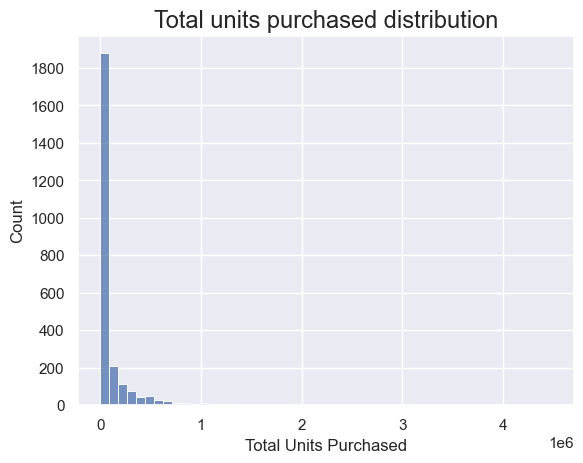

In [19]:
sns.histplot(hh_shopping["total_units_purchased"], bins=50)
plt.title("Total units purchased distribution", fontsize=17)
plt.xlabel("Total Units Purchased")
plt.ylabel("Count")
plt.yticks(np.arange(0, 2000, 200))
plt.show()

#### Average days between trips distribution
Most households returned fairly regularly, while some had much longer gaps between shopping trips.

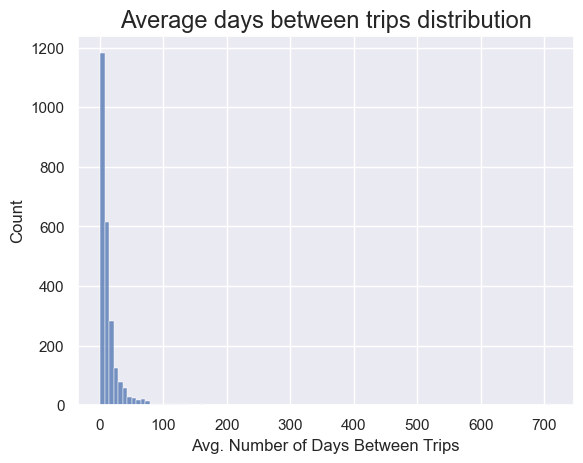

In [20]:
sns.histplot(hh_shopping["avg_days_between_trips"], bins=100)
plt.title("Average days between trips distribution", fontsize=17)
plt.xlabel("Avg. Number of Days Between Trips")
plt.ylabel("Count")
plt.yticks(np.arange(0, 1300, 200))
plt.show()

#### Average basket size distribution
Most households had relatively small baskets, with a few showing much larger average quantities per trip.

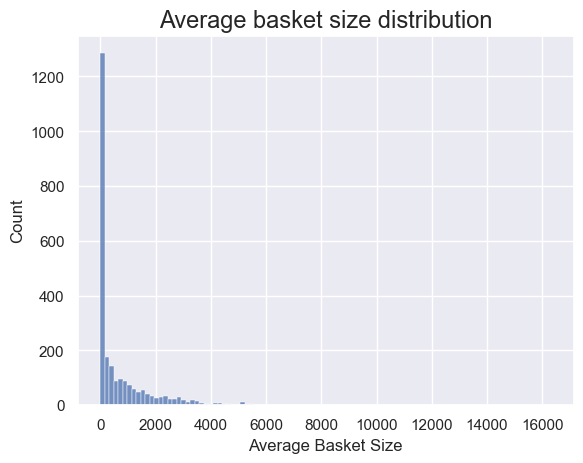

In [21]:
sns.histplot(hh_shopping["avg_basket_size"], bins=100)
plt.title("Average basket size distribution", fontsize=17)
plt.xlabel("Average Basket Size")
plt.ylabel("Count")
plt.show()

#### Total units purchased vs. average basket size
Most households have relatively low total units and average basket sizes, while a few extreme observations make the overall relationship difficult to interpret.

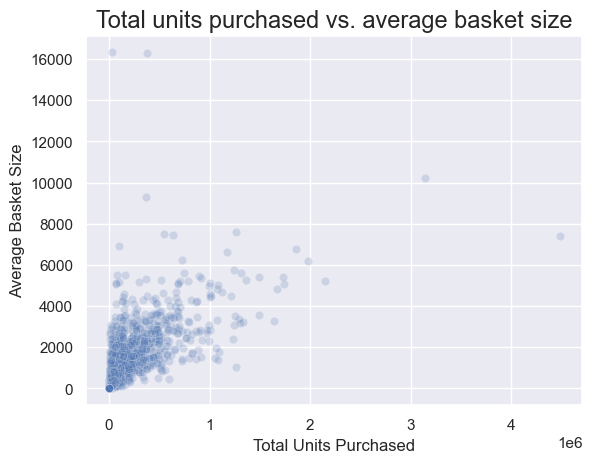

In [22]:
sns.scatterplot(
    data=hh_shopping, 
    x="total_units_purchased", 
    y="avg_basket_size",
    alpha=0.2
)
plt.title("Total units purchased vs. average basket size", fontsize=17)
plt.xlabel("Total Units Purchased")
plt.ylabel("Average Basket Size")
plt.show()

#### Export data

In [23]:
hh_shopping.to_parquet(
    CLEAN_DATA_DIR / "02_household_shopping_data_analysis.parquet", index=False
)